# **Machine Learning Project: Movie Recommendation System**

**Step 1 — Download the dataset**

Download the [TMDB Movie Metadata dataset on Kaggle.](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?resource=download)

find these two files:
- tmdb_5000_movies.csv
- tmdb_5000_credits.csv

# **Step 2 - Import the libraries**

In [1]:
import pandas as pd
import numpy as np
import ast

from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# **Step 3 - Load and explore the dataset**

In [2]:
movies = pd.read_csv("tmdb_5000_movies.csv")
credits = pd.read_csv("tmdb_5000_credits.csv")

print("Movies:", movies.shape)
print("Credits:", credits.shape)

display(movies.head())
display(credits.head())

Movies: (4803, 20)
Credits: (4803, 4)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [5]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

In [4]:
movies.isnull().sum()

,0
budget,0
genres,0
homepage,3091
id,0
keywords,0
original_language,0
original_title,0
overview,3
popularity,0
production_companies,0


In [6]:
movies.duplicated().sum()

np.int64(0)

# **Step 4 - Merge the datasets**

The movie metadata file has a column called id, while the credits file has movie_id.

Both identify the same movie.

In [7]:
df = movies.merge(
    credits,
    left_on="id",
    right_on="movie_id",
    suffixes=("", "_credits")
)

print(df.shape)

(4803, 24)


We merge on IDs rather than titles to avoid matching two different movies with the same name.

Next, select the columns relevant to our recommendations:

In [8]:
df = df[
    ["id", "title", "overview",
     "genres", "keywords", "cast", "crew"]
].copy()

df = df.dropna()
df = df.drop_duplicates(subset="id")
df = df.reset_index(drop=True)

display(df.head())

,id,title,overview,genres,keywords,cast,crew
0,19995,Avatar,"In the 22nd century, a paraplegic Marine is di...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...","[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...","[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,A cryptic message from Bond’s past sends him o...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...","[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,Following the death of District Attorney Harve...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...","[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...","[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"John Carter is a war-weary, former military ca...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 818, ""name"": ""based on novel""}, {""id"":...","[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


# **Step 5 - Understand the unusual data format**

One of the most important details in this project is that some CSV cells contain JSON-like lists stored as strings.

For example, a genre cell may look like:

'[{"id": 28, "name": "Action"},
  {"id": 12, "name": "Adventure"}]'

This is a string, not a Python list.

We want:

["Action", "Adventure"]

Use ast.literal_eval() to safely parse this format:

In [9]:
def extract_names(value):
    items = ast.literal_eval(value)
    return [item["name"] for item in items]

df["genres"] = df["genres"].apply(extract_names)
df["keywords"] = df["keywords"].apply(extract_names)

Why not use  eval() ? Because eval() can execute arbitrary Python expressions. ast.literal_eval() is safer for this type of structured literal data.

# **Step 6 - Extract the cast and director**

We only need the first three cast members, following the video's approach.

In [10]:
def extract_cast(value):
    items = ast.literal_eval(value)
    return [item["name"] for item in items[:3]]

df["cast"] = df["cast"].apply(extract_cast)

The crew contains many roles: producers, editors, writers, directors, and more.

We want only the director.

In [11]:
def extract_director(value):
    items = ast.literal_eval(value)

    return [
        item["name"]
        for item in items
        if item["job"] == "Director"
    ]

df["crew"] = df["crew"].apply(extract_director)

Now each movie has lists of genres, keywords, actors and directors.

# **Step 7 - Prepare the text features**

First, convert each movie overview into a list of words.

In [12]:
df["overview"] = df["overview"].apply(
    lambda text: text.split()
)

Then remove spaces from multiword names and labels.

In [13]:
def remove_spaces(items):
    return [item.replace(" ", "") for item in items]

for column in ["genres", "keywords", "cast", "crew"]:
    df[column] = df[column].apply(remove_spaces)

# **Step 8 - Create the tags feature**

This is the most important feature engineering step.

We combine all the information about each movie into one text representation.

In [14]:
df["tags"] = (
    df["overview"]
    + df["genres"]
    + df["keywords"]
    + df["cast"]
    + df["crew"]
)

df["tags"] = df["tags"].apply(
    lambda words: " ".join(words).lower()
)

model_df = df[["id", "title", "tags"]].copy()

display(model_df.head())

,id,title,tags
0,19995,Avatar,"in the 22nd century, a paraplegic marine is di..."
1,285,Pirates of the Caribbean: At World's End,"captain barbossa, long believed to be dead, ha..."
2,206647,Spectre,a cryptic message from bond’s past sends him o...
3,49026,The Dark Knight Rises,following the death of district attorney harve...
4,49529,John Carter,"john carter is a war-weary, former military ca..."


**A simplified example might look like:**

avatar:

a marine travels to an alien planet

action adventure sciencefiction

alienplanet samworthington

zoesaldana jamescameron

Now we have converted several different types of metadata into a single text feature.

**Why is this useful?**

Because we can use text processing algorithms to compare movies based on their content.

# **Step 9 - Apply stemming**

Stemming reduces related word forms to a common root.

For example:

Original       ----------- word	Stem

loved	         -----------    love

loving	 -----------     love

connected	-----------connect

connections	----------- connect


This helps reduce vocabulary variation.

In [15]:
stemmer = PorterStemmer()

def stem_text(text):
    return " ".join(
        stemmer.stem(word)
        for word in text.split()
    )

model_df["tags"] = model_df["tags"].apply(stem_text)

Stemming is a simple baseline technique. It can occasionally distort names, so later we can experiment with applying it only to the overview text.

# **Step 10 - Convert text into numbers**

Machine learning algorithms generally need numerical representations rather than raw text.

Use **CountVectorizer**, a bag-of-words technique.

In [16]:
vectorizer = CountVectorizer(
    max_features=5000,
    stop_words="english"
)

vectors = vectorizer.fit_transform(
    model_df["tags"]
)

print(vectors.shape)

(4800, 5000)


If we have 4,806 movies and 5,000 selected features, the result will have this shape: (4806, 5000)

The actual number of columns can be smaller if the dataset has fewer than 5,000 eligible terms.

# **What does this matrix mean?**

Imagine our vocabulary contains only five words:

space, alien, love, war, future

A simplified representation might be:

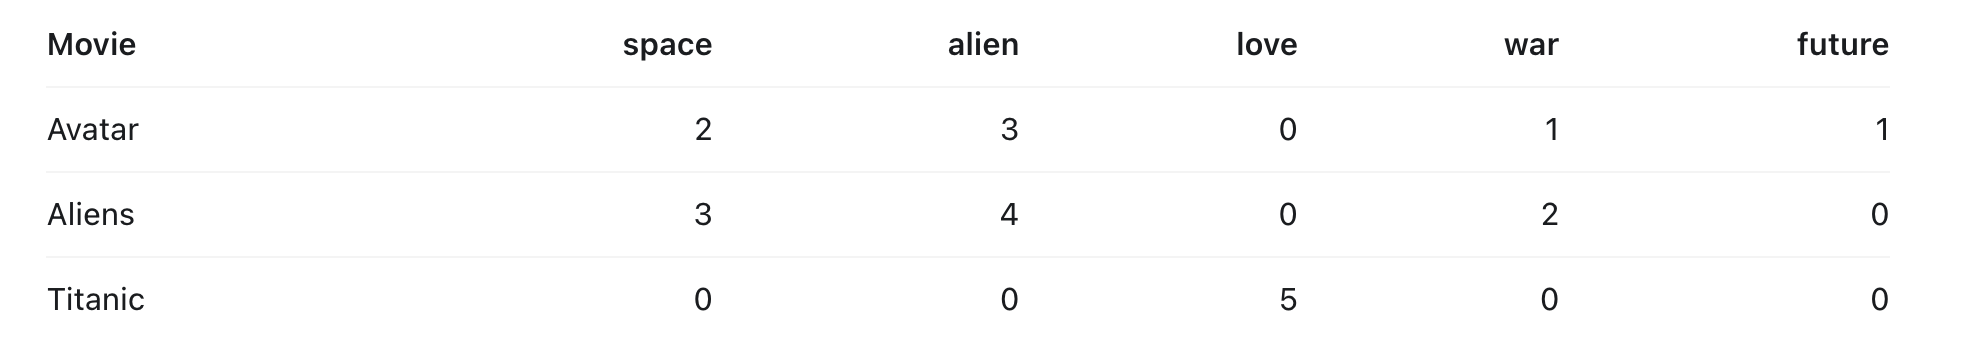

Each number represents the frequency of a word in the movie's tags.

Avatar and Aliens share several terms. Titanic is very different.

In the actual project, the vector has up to 5,000 dimensions.

# **Step 11 - Calculate cosine similarity**

Now we want to measure how similar the movie vectors are.

Cosine similarity measures the angle between two vectors.


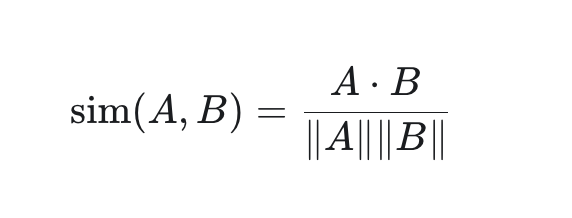

For our nonnegative word-count vectors, the score ranges from 0 to 1:
- 1: Vectors point in the same direction.
- 0: No shared nonzero features.
- 0.7: Relatively strong similarity.

download.svg

Calculate the similarity matrix:

In [17]:
similarity = cosine_similarity(vectors)

print(similarity.shape)

(4800, 4800)


For 4,806 movies, the result is a matrix of:

4806 X 4806

Each entry represents the similarity between two movies.

For example:

In [18]:
similarity[0][1]

np.float64(0.08346223261119858)

returns the similarity between the first and second movies.

# **Step 12 - Build the recommendation function**

Now we have everything needed to recommend movies.

In [19]:
def recommend(movie_title, top_n=5):

    matches = model_df[
        model_df["title"].str.lower()
        == movie_title.lower()
    ]

    if matches.empty:
        return "Movie not found."

    index = matches.index[0]

    scores = list(enumerate(similarity[index]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    recommendations = []

    for movie_index, score in scores:
        if movie_index == index:
            continue

        recommendations.append({
            "title": model_df.iloc[movie_index]["title"],
            "similarity": round(float(score), 3)
        })

        if len(recommendations) == top_n:
            break

    return pd.DataFrame(recommendations)

Let's understand the logic:
1. Find the movie the user requested.
2. Get its row index.
3. Retrieve its similarity scores against all movies.
4. Sort the scores from highest to lowest.
5. Exclude the original movie.
6. Return the five closest matches.

Test it:

In [20]:
recommend("Avatar")

,title,similarity
0,Aliens vs Predator: Requiem,0.287
1,Aliens,0.269
2,Falcon Rising,0.261
3,Independence Day,0.256
4,Titan A.E.,0.250


In [22]:
recommend("Titanic")


,title,similarity
0,The Notebook,0.256
1,Under the Same Moon,0.246
2,Ghost Ship,0.241
3,The Bounty,0.228
4,Pirates of the Caribbean: On Stranger Tides,0.219


In [23]:
recommend("The Dark Knight")

,title,similarity
0,The Dark Knight Rises,0.423
1,Batman Begins,0.402
2,Batman Returns,0.331
3,Batman Forever,0.294
4,Batman,0.261


In [24]:
recommend("Iron Man")

,title,similarity
0,Iron Man 3,0.437
1,Iron Man 2,0.404
2,Avengers: Age of Ultron,0.336
3,The Avengers,0.271
4,Captain America: Civil War,0.264


# **Evaluate your recommendation system**

A recommendation system should not be judged only by whether its suggestions look reasonable.

**Experiment 1 — Compare CountVectorizer with TF-IDF**

CountVectorizer counts words. TF-IDF also considers how common or rare those words are across movies.



In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

tfidf_vectors = tfidf.fit_transform(
    model_df["tags"]
)

tfidf_similarity = cosine_similarity(tfidf_vectors)

Now compare the recommendations from both methods.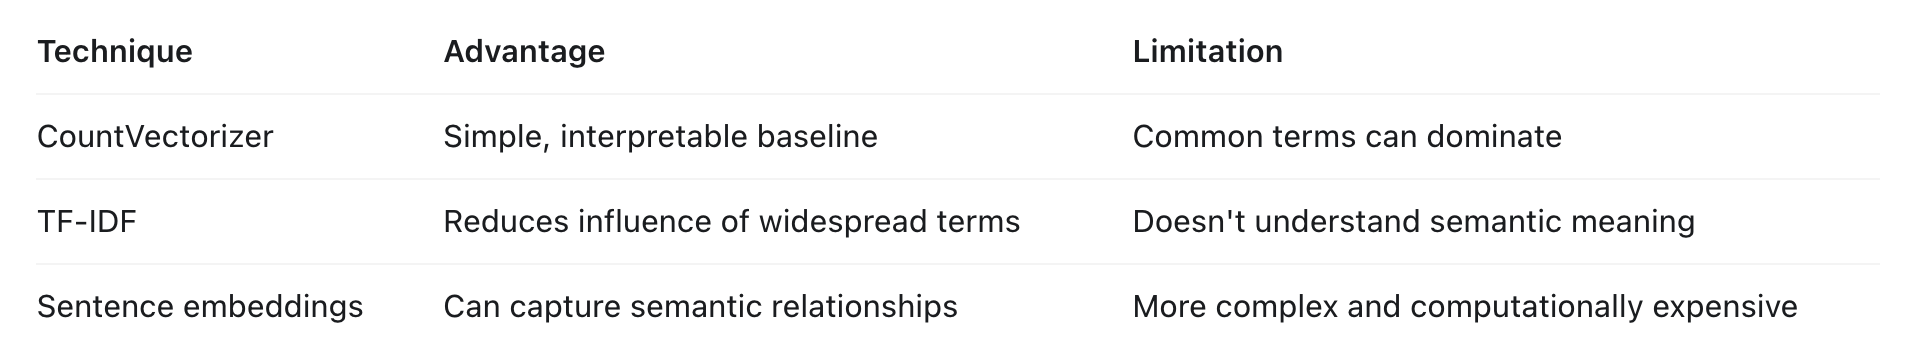

**Experiment 2 - Check recommendation relevance**

Create a small evaluation set of movies and manually inspect their top five recommendations.

For each recommendation, assign a relevance rating:
- 0 — Not relevant
- 1 — Somewhat relevant
- 2 — Highly relevant
You can then compute a metric such as nDCG@5 to evaluate ranking quality.

This is a small human evaluation, not an objective ground-truth benchmark. For a more rigorous evaluation, you would need reliable relevance judgments or user interaction data.

**Experiment 3 — Study feature importance**

Try building the system with different feature combinations:

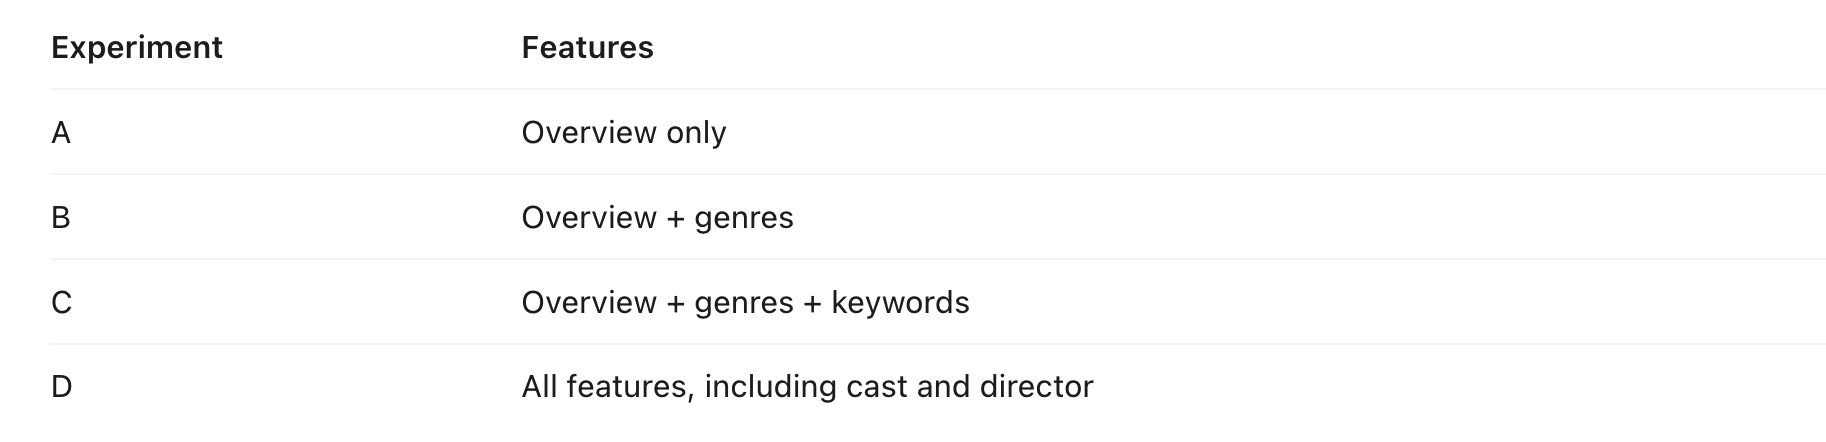

Compare how recommendations change. This is called an ablation study, and it is a useful way to demonstrate analytical thinking.